# Project part 4 – Machine Learning


## 1. Introduction

<div style="background-color: #eaf3fa; padding: 22px; border-radius: 12px; border-left: 5px solid #4a90c3; color: #243746;">

<h3 style="margin-top: 0;">Use of AI</h3>

<p>
I used ChatGPT throughout this project to help me understand the assignment, write and improve code, solve errors and explain concepts that were new to me. I also used it to discuss different solutions, develop the design of my Streamlit application. I tested the suggested code along the way and tried to understand how it worked before moving on. As i found it difficult to make the forecast model, especially with other data, I used chatGPT to discuss and help me provide a working solution (Although different AI tools did not find a solution to my problem with datasources)
</p>

</div>

<div style="background-color: #eaf3fa; padding: 22px; border-radius: 12px; border-left: 5px solid #4a90c3; color: #243746;">

<h3 style="margin-top: 0;">Work Log and Reflection</h3>

<p>
I started this project by reading through the assignment and trying to understand how I wanted to structure my application. There were quite a lot of different tasks, so I decided to work on one part at a time instead of trying to do everything at once.
</p>

<p>
I wanted to make my Streamlit application more organised and easier to use. I divided the pages into different categories and created a Home page with an interactive map. One of the challenges was to make the selected area follow the user when moving between pages. I solved this by using session state, which I now understand better than I did before.
</p>

<p>
I also spent some time working on the map and how to display temperature and precipitation for the different areas. I wanted the user to be able to explore the data themselves rather than only looking at predefined plots.
</p>

<p>
Working with different data sources was a bit challenging, especially when it came to time zones and different time resolutions. I chose to work with weekly data when combining weather data and reservoir statistics, since the reservoir data is already given weekly.
</p>

<p>
The forecasting part was probably one of the more difficult parts of this project. I had some problems with downloading and loading larger amounts of weather data. I also got an error related to a corrupted Parquet file. Since I had limited time, I decided to focus on getting the forecasting model to work without weather data first. I also wanted to make the forecasting more interesting for the user, so I created a separate animated map for the predicted fill levels.
</p>

<p>
One of the parts I enjoyed the most was working on the design of the application. I really liked the design and colours on Norsk Hydro's website and used this as inspiration for my own theme. I created a shared colour palette and went through each page to replace the static plots with interactive Plotly plots. I tested the pages individually before moving on to the next one.
</p>

<p>
For the bonus exercise, I chose waiting time. I realised that I had already implemented several things related to this during the development of my application, such as caching, progress bars, spinners and local storage of weather data. I therefore went through the existing code to check what was already implemented.
</p>


<p>
Overall, I feel that I have become more comfortable working with Streamlit and organising a larger project. I still find some parts of the programming difficult, especially when combining several functions and data sources, but I am starting to understand how the different parts of the application work together.
</p>

</div>

## 2. Currency Exchange Rates – Norges Bank API


In [11]:
import requests

def get_exchange_rates(currency, start_date, end_date):
    # Build the API URL for the selected currency
    url = f"https://data.norges-bank.no/api/data/EXR/B.{currency}.NOK.SP"

    # Define the time period and response format
    params = {
        "startPeriod": start_date,
        "endPeriod": end_date,
        "format": "sdmx-json",
        "locale": "no"
    }

    # Send a request to Norges Bank
    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()

    # Convert the response to a Python dictionary
    data = response.json()

    return data

In [12]:
usd_data = get_exchange_rates("USD", "2024-01-01", "2025-12-31")

usd_data.keys()

dict_keys(['meta', 'data'])

In [13]:
# Show the first five USD exchange rate observations
usd_series = usd_data["data"]["dataSets"][0]["series"]

usd_observations = list(usd_series.values())[0]["observations"]

list(usd_observations.items())[:5]

[('0', ['10.2971']),
 ('1', ['10.3672']),
 ('2', ['10.3027']),
 ('3', ['10.3553']),
 ('4', ['10.38'])]

In [14]:
# Check the structure of the USD exchange rate data
usd_data["data"]["structure"].keys()

dict_keys(['links', 'name', 'names', 'description', 'descriptions', 'dimensions', 'attributes'])

In [15]:
# Check how the dimensions are organized
usd_data["data"]["structure"]["dimensions"].keys()

dict_keys(['dataset', 'series', 'observation'])

In [16]:
# Show the dimensions for individual observations
usd_data["data"]["structure"]["dimensions"]["observation"]

[{'id': 'TIME_PERIOD',
  'name': 'Tidsperiode',
  'description': 'Tidsperioden eller tidspunktet for den målte observasjonen.',
  'keyPosition': 4,
  'role': 'time',
  'values': [{'start': '2024-01-02T00:00:00',
    'end': '2024-01-02T23:59:59',
    'id': '2024-01-02',
    'name': '2024-01-02'},
   {'start': '2024-01-03T00:00:00',
    'end': '2024-01-03T23:59:59',
    'id': '2024-01-03',
    'name': '2024-01-03'},
   {'start': '2024-01-04T00:00:00',
    'end': '2024-01-04T23:59:59',
    'id': '2024-01-04',
    'name': '2024-01-04'},
   {'start': '2024-01-05T00:00:00',
    'end': '2024-01-05T23:59:59',
    'id': '2024-01-05',
    'name': '2024-01-05'},
   {'start': '2024-01-08T00:00:00',
    'end': '2024-01-08T23:59:59',
    'id': '2024-01-08',
    'name': '2024-01-08'},
   {'start': '2024-01-09T00:00:00',
    'end': '2024-01-09T23:59:59',
    'id': '2024-01-09',
    'name': '2024-01-09'},
   {'start': '2024-01-10T00:00:00',
    'end': '2024-01-10T23:59:59',
    'id': '2024-01-10',
    

In [17]:
# Extract the dates from the API response
time_values = usd_data["data"]["structure"]["dimensions"]["observation"][0]["values"]

dates = [item["id"] for item in time_values]

# Show the first five dates
dates[:5]

['2024-01-02', '2024-01-03', '2024-01-04', '2024-01-05', '2024-01-08']

In [18]:
import pandas as pd

# Match each exchange rate with its corresponding date
rates = [float(usd_observations[str(i)][0]) for i in range(len(dates))]

# Create a DataFrame with dates and USD exchange rates
usd_df = pd.DataFrame({
    "Date": pd.to_datetime(dates),
    "USD_NOK": rates
})

# Show the first five rows
usd_df.head()

,Date,USD_NOK
0,2024-01-02,10.2971
1,2024-01-03,10.3672
2,2024-01-04,10.3027
3,2024-01-05,10.3553
4,2024-01-08,10.3800


In [19]:
# Check that the number of dates matches the number of exchange rates
print("Number of dates:", len(dates))
print("Number of exchange rates:", len(usd_observations))

Number of dates: 502
Number of exchange rates: 502


In [20]:
import requests
import pandas as pd

def get_exchange_rates_df(currency, start_date, end_date):
    # Build the API URL for the selected currency
    url = f"https://data.norges-bank.no/api/data/EXR/B.{currency}.NOK.SP"

    # Define the time period and response format
    params = {
        "startPeriod": start_date,
        "endPeriod": end_date,
        "format": "sdmx-json",
        "locale": "no"
    }

    # Send a request to Norges Bank
    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()

    # Convert the response to a Python dictionary
    data = response.json()

    # Extract dates from the API response
    time_values = data["data"]["structure"]["dimensions"]["observation"][0]["values"]
    dates = [item["id"] for item in time_values]

    # Extract exchange rate observations
    series = data["data"]["dataSets"][0]["series"]
    observations = list(series.values())[0]["observations"]

    # Match exchange rates with their corresponding dates
    rates = [float(observations[str(i)][0]) for i in range(len(dates))]

    # Create a DataFrame
    df = pd.DataFrame({
        "Date": pd.to_datetime(dates),
        f"{currency}_NOK": rates
    })

    return df

In [21]:
# Download USD exchange rates as a DataFrame
usd_df = get_exchange_rates_df("USD", "2024-01-01", "2025-12-31")

usd_df.head()

,Date,USD_NOK
0,2024-01-02,10.2971
1,2024-01-03,10.3672
2,2024-01-04,10.3027
3,2024-01-05,10.3553
4,2024-01-08,10.3800


In [22]:
# Download EUR exchange rates as a DataFrame
eur_df = get_exchange_rates_df("EUR", "2024-01-01", "2025-12-31")

eur_df.head()

,Date,EUR_NOK
0,2024-01-02,11.2815
1,2024-01-03,11.3200
2,2024-01-04,11.2845
3,2024-01-05,11.3090
4,2024-01-08,11.3620


In [23]:
# Combine USD and EUR exchange rates using their dates
exchange_rates_df = pd.merge(usd_df, eur_df, on="Date", how="outer")

# Sort the DataFrame by date
exchange_rates_df = exchange_rates_df.sort_values("Date").reset_index(drop=True)

exchange_rates_df.head()

,Date,USD_NOK,EUR_NOK
0,2024-01-02,10.2971,11.2815
1,2024-01-03,10.3672,11.3200
2,2024-01-04,10.3027,11.2845
3,2024-01-05,10.3553,11.3090
4,2024-01-08,10.3800,11.3620


In [24]:
# Check the size of the dataset
print("Shape:", exchange_rates_df.shape)

# Check for missing values
print("\nMissing values:")
print(exchange_rates_df.isna().sum())

# Check the data types
print("\nData types:")
print(exchange_rates_df.dtypes)

Shape: (502, 3)

Missing values:
Date       0
USD_NOK    0
EUR_NOK    0
dtype: int64

Data types:
Date       datetime64[us]
USD_NOK           float64
EUR_NOK           float64
dtype: object


In [25]:
# Inspect the time information in the Norges Bank API response
time_values = usd_data["data"]["structure"]["dimensions"]["observation"][0]["values"]

# Show the first time period
time_values[0]

{'start': '2024-01-02T00:00:00',
 'end': '2024-01-02T23:59:59',
 'id': '2024-01-02',
 'name': '2024-01-02'}

### Norges Bank API

The Norges Bank API provides daily exchange rates with dates in the format `YYYY-MM-DD`. The API response also includes start and end timestamps for each observation period, but these do not contain explicit timezone information.

Therefore, the exchange rate data is treated as daily observations rather than timezone-specific timestamps. When combining these data with other sources, the dates should be aligned carefully.

## 3. Investigating timezone for the different APIs

In [26]:
# Retrieve reservoir data from the NVE API
nve_url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

nve_response = requests.get(nve_url, timeout=30)
nve_response.raise_for_status()

nve_data = nve_response.json()

# Inspect the original date format
print(nve_data[0]["dato_Id"])

2020-11-15


### NVE Magasinstatistikk

The NVE Magasinstatistikk API provides dates in the format `YYYY-MM-DD`, without a specific time or timezone offset. The `dato_Id` field can therefore be treated as a calendar date rather than a timezone-aware timestamp.

When combining NVE data with other sources, the dates and observation frequency must be considered to ensure correct alignment.

### ENTSO-E API

The ENTSO-E API provides timestamps in UTC, indicated by the `Z` suffix. For example, `2024-10-14T16:00Z` represents 16:00 UTC, which corresponds to 18:00 in Norway during daylight saving time.

The data also has a resolution of `PT60M`, meaning hourly observations. When combining ENTSO-E data with other datasets, timestamps may need to be converted to the `Europe/Oslo` timezone. This conversion must account for daylight saving time.

### Open-Meteo API

The Open-Meteo API allows users to specify a timezone when requesting weather data. In Project 3, no timezone parameter was specified, so the default UTC timezone was used.

The hourly ERA5 weather data was converted to pandas timestamps using `utc=True`, making the timestamps timezone-aware. This is useful when combining Open-Meteo data with ENTSO-E data, which also uses UTC timestamps.

If local Norwegian time is needed, the timestamps can be converted to `Europe/Oslo`, accounting for daylight saving time.

## 4. Retreiving data from all sources needed further

In [27]:
# Convert NVE API data into a DataFrame
nve_df = pd.DataFrame(nve_data)

# Convert the date column to datetime
nve_df["dato_Id"] = pd.to_datetime(nve_df["dato_Id"])

# Sort the data chronologically
nve_df = nve_df.sort_values("dato_Id").reset_index(drop=True)

nve_df.head()

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-01-08,VASS,3,1995,1,0.554572,28.155403,15.614198,0001-01-01T00:00:00,0.661426,-0.106854
1,1995-01-08,NO,0,1995,1,0.603830,87.437580,52.797410,0001-01-01T00:00:00,0.752631,-0.148802
2,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869
3,1995-01-08,VASS,2,1995,1,0.608856,23.237715,14.148431,0001-01-01T00:00:00,0.744693,-0.135837
4,1995-01-08,EL,2,1995,1,0.630947,34.043590,21.479713,0001-01-01T00:00:00,0.777604,-0.146657


In [28]:
def convert_to_norwegian_time(df, time_column):
    # Create a copy to avoid modifying the original DataFrame
    df = df.copy()

    # Interpret the timestamps as UTC
    df[time_column] = pd.to_datetime(df[time_column], utc=True)

    # Convert UTC timestamps to Norwegian local time
    df[time_column] = df[time_column].dt.tz_convert("Europe/Oslo")

    return df

In [30]:
from pathlib import Path

# Search for the saved ENTSO-E file in the project
files = list(Path("..").rglob("entsoe_backup.pkl"))

# Show all matching file paths
print(files)

[WindowsPath('../notebooks/entsoe_backup.pkl')]


In [31]:
import pandas as pd
from pathlib import Path

# Define the correct path to the saved ENTSO-E file
entsoe_file = Path("../notebooks/entsoe_backup.pkl")

# Load the saved ENTSO-E data
entsoe_df = pd.read_pickle(entsoe_file)

# Check the data structure
print("Data type:", type(entsoe_df))
print("Shape:", entsoe_df.shape)

entsoe_df.head()

Data type: <class 'pandas.DataFrame'>
Shape: (1034984, 6)


,out_area,in_area,direction,timestamp,power_mw,energy_mwh
0,NO1,SE3,Export,2024-10-14 16:00:00+00:00,218.75,218.75
1,NO1,SE3,Export,2024-10-14 17:00:00+00:00,0.00,0.00
2,NO1,SE3,Export,2024-10-14 18:00:00+00:00,0.00,0.00
3,NO1,SE3,Export,2024-10-14 19:00:00+00:00,0.00,0.00
4,NO1,SE3,Export,2024-10-14 20:00:00+00:00,0.00,0.00


In [32]:
# Convert ENTSO-E timestamps to Norwegian local time
entsoe_oslo_df = convert_to_norwegian_time(entsoe_df, "timestamp")

# Show the first five rows
entsoe_oslo_df.head()

,out_area,in_area,direction,timestamp,power_mw,energy_mwh
0,NO1,SE3,Export,2024-10-14 18:00:00+02:00,218.75,218.75
1,NO1,SE3,Export,2024-10-14 19:00:00+02:00,0.00,0.00
2,NO1,SE3,Export,2024-10-14 20:00:00+02:00,0.00,0.00
3,NO1,SE3,Export,2024-10-14 21:00:00+02:00,0.00,0.00
4,NO1,SE3,Export,2024-10-14 22:00:00+02:00,0.00,0.00


In [33]:
from pathlib import Path

# Search for saved weather data files from Project 3
weather_files = list(Path("..").rglob("*.parquet"))

# Show the file paths
for file in weather_files:
    print(file)

..\data\weather_data\NO3_2024-01-01_2024-12-31_batch_0_size_10.parquet
..\data\weather_data\NO3_2024-01-01_2024-12-31_batch_0_size_3.parquet
..\data\weather_data\NO3_2024-01-01_2024-12-31_batch_100_size_10.parquet
..\data\weather_data\NO3_2024-01-01_2024-12-31_batch_10_size_10.parquet
..\data\weather_data\NO3_2024-01-01_2024-12-31_batch_110_size_10.parquet
..\data\weather_data\NO3_2024-01-01_2024-12-31_batch_120_size_10.parquet
..\data\weather_data\NO3_2024-01-01_2024-12-31_batch_12_size_3.parquet
..\data\weather_data\NO3_2024-01-01_2024-12-31_batch_130_size_10.parquet
..\data\weather_data\NO3_2024-01-01_2024-12-31_batch_140_size_10.parquet
..\data\weather_data\NO3_2024-01-01_2024-12-31_batch_150_size_10.parquet
..\data\weather_data\NO3_2024-01-01_2024-12-31_batch_15_size_3.parquet
..\data\weather_data\NO3_2024-01-01_2024-12-31_batch_160_size_10.parquet
..\data\weather_data\NO3_2024-01-01_2024-12-31_batch_170_size_10.parquet
..\data\weather_data\NO3_2024-01-01_2024-12-31_batch_180_size

In [34]:
# Load saved Open-Meteo weather data from Project 3
weather_file = Path("../data/weather_data/NO3_weather_2024.parquet")

weather_df = pd.read_parquet(weather_file)

# Inspect the data structure
print("Shape:", weather_df.shape)
print("\nColumns:", weather_df.columns.tolist())
print("\nData types:")
print(weather_df.dtypes)

weather_df.head()

Shape: (8784000, 5)

Columns: ['time', 'latitude', 'longitude', 'temperature_2m', 'precipitation']

Data types:
time              datetime64[us, UTC]
latitude                      float64
longitude                     float64
temperature_2m                float32
precipitation                 float32
dtype: object


,time,latitude,longitude,temperature_2m,precipitation
0,2024-01-01 00:00:00+00:00,61.722342,9.04807,-7.455500,0.1
1,2024-01-01 01:00:00+00:00,61.722342,9.04807,-7.655499,0.1
2,2024-01-01 02:00:00+00:00,61.722342,9.04807,-7.755500,0.1
3,2024-01-01 03:00:00+00:00,61.722342,9.04807,-7.955500,0.1
4,2024-01-01 04:00:00+00:00,61.722342,9.04807,-8.055500,0.1


In [35]:
# Convert Open-Meteo timestamps to Norwegian local time
weather_oslo_df = convert_to_norwegian_time(weather_df, "time")

# Check the converted timestamps
print(weather_oslo_df["time"].dtype)

weather_oslo_df.head()

datetime64[us, Europe/Oslo]


,time,latitude,longitude,temperature_2m,precipitation
0,2024-01-01 01:00:00+01:00,61.722342,9.04807,-7.455500,0.1
1,2024-01-01 02:00:00+01:00,61.722342,9.04807,-7.655499,0.1
2,2024-01-01 03:00:00+01:00,61.722342,9.04807,-7.755500,0.1
3,2024-01-01 04:00:00+01:00,61.722342,9.04807,-7.955500,0.1
4,2024-01-01 05:00:00+01:00,61.722342,9.04807,-8.055500,0.1


## 5. Reservoar filling Forecast

In [36]:
# Select reservoir data for Norway as a whole
nve_norway_df = nve_df[
    (nve_df["omrType"] == "NO") &
    (nve_df["omrnr"] == 0)
].copy()

# Sort observations chronologically
nve_norway_df = nve_norway_df.sort_values("dato_Id")

# Check the number of observations and date range
print("Number of observations:", len(nve_norway_df))
print("First date:", nve_norway_df["dato_Id"].min())
print("Last date:", nve_norway_df["dato_Id"].max())

# Display the first five rows
nve_norway_df.head()

Number of observations: 1663
First date: 1995-01-08 00:00:00
Last date: 2026-11-15 00:00:00


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
1,1995-01-08,NO,0,1995,1,0.603830,87.43758,52.797410,0001-01-01T00:00:00,0.752631,-0.148802
17,1995-01-15,NO,0,1995,2,0.578233,87.43758,50.559322,0001-01-01T00:00:00,0.603830,-0.025596
23,1995-01-22,NO,0,1995,3,0.558350,87.43758,48.820730,0001-01-01T00:00:00,0.578233,-0.019884
27,1995-01-29,NO,0,1995,4,0.530596,87.43758,46.393990,0001-01-01T00:00:00,0.558350,-0.027754
38,1995-02-05,NO,0,1995,5,0.502755,87.43758,43.959710,0001-01-01T00:00:00,0.530596,-0.027840


In [37]:
# Check for missing values and duplicate dates
print("Missing filling values:",
      nve_norway_df["fyllingsgrad"].isna().sum())

print("Duplicate dates:",
      nve_norway_df["dato_Id"].duplicated().sum())

# Check the time difference between observations
week_differences = nve_norway_df["dato_Id"].diff().dt.days

print("\nDays between observations:")
print(week_differences.value_counts().sort_index())

Missing filling values: 0
Duplicate dates: 0

Days between observations:
dato_Id
7.0    1662
Name: count, dtype: int64


In [38]:
# Select the columns needed for forecasting
forecast_df = nve_norway_df[["dato_Id", "fyllingsgrad"]].copy()

# Rename columns to make them easier to work with
forecast_df = forecast_df.rename(columns={
    "dato_Id": "date",
    "fyllingsgrad": "filling"
})

# Use the date as the DataFrame index
forecast_df = forecast_df.set_index("date")

# Display the first five observations
forecast_df.head()

,filling
date,
1995-01-08,0.603830
1995-01-15,0.578233
1995-01-22,0.558350
1995-01-29,0.530596
1995-02-05,0.502755


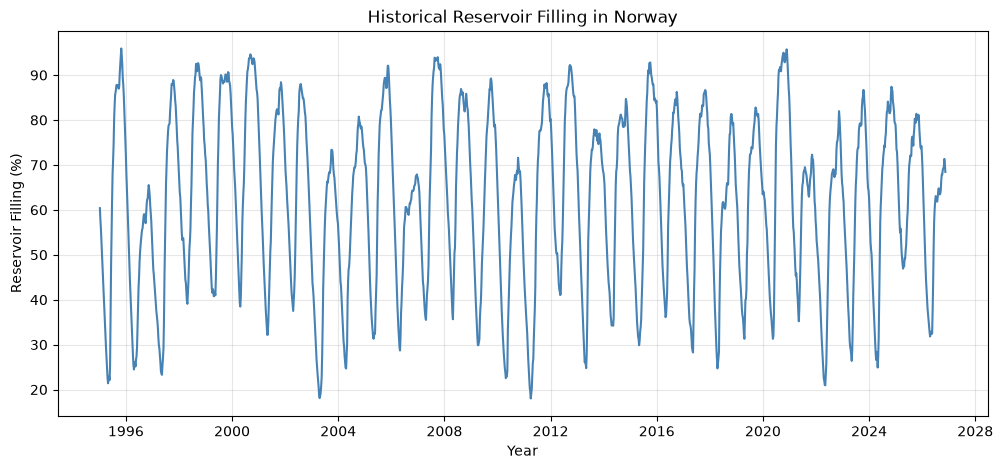

In [39]:
import matplotlib.pyplot as plt

# Plot historical reservoir filling levels
plt.figure(figsize=(12, 5))

plt.plot(
    forecast_df.index,
    forecast_df["filling"] * 100,
    color="steelblue"
)

# Add title and axis labels
plt.title("Historical Reservoir Filling in Norway")
plt.xlabel("Year")
plt.ylabel("Reservoir Filling (%)")

# Add a grid to make the plot easier to read
plt.grid(alpha=0.3)

plt.show()

In [40]:
# Create a copy for feature engineering
model_df = forecast_df.copy()

# Add reservoir filling from the previous week
model_df["lag_1"] = model_df["filling"].shift(1)

# Add week number to capture seasonal patterns
model_df["week"] = model_df.index.isocalendar().week.astype(int)

# Remove the first row, which has no previous observation
model_df = model_df.dropna()

# Display the first five rows
model_df.head()

,filling,lag_1,week
date,,,
1995-01-15,0.578233,0.603830,2
1995-01-22,0.558350,0.578233,3
1995-01-29,0.530596,0.558350,4
1995-02-05,0.502755,0.530596,5
1995-02-12,0.478458,0.502755,6


In [41]:
# Split the data chronologically
train_df = model_df[model_df.index < "2024-01-01"]
test_df = model_df[
    (model_df.index >= "2024-01-01") &
    (model_df.index < "2026-01-01")
]

# Check the training and test periods
print("Training observations:", len(train_df))
print("Test observations:", len(test_df))

print("\nTraining period:")
print(train_df.index.min(), "to", train_df.index.max())

print("\nTest period:")
print(test_df.index.min(), "to", test_df.index.max())

Training observations: 1512
Test observations: 104

Training period:
1995-01-15 00:00:00 to 2023-12-31 00:00:00

Test period:
2024-01-07 00:00:00 to 2025-12-28 00:00:00


In [43]:
%pip install river

   ---------------------------------------- 0.0/2.7 MB ? eta -:--:--
   -------------------------- ------------- 1.8/2.7 MB 9.1 MB/s eta 0:00:01
   ---------------------------------------- 2.7/2.7 MB 8.8 MB/s  0:00:00

  Attempting uninstall: narwhals

    Found existing installation: narwhals 2.27.1

   ---------------------------------------- 0/2 [narwhals]
    Uninstalling narwhals-2.27.1:
   ---------------------------------------- 0/2 [narwhals]
      Successfully uninstalled narwhals-2.27.1
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   -----------------------

In [44]:
# Import River for online machine learning
import river

# Check the installed River version
print("River version:", river.__version__)

River version: 0.27.0


In [45]:
from river import linear_model, preprocessing, optim

# Create a River regression model
model = (
    preprocessing.StandardScaler() |
    linear_model.LinearRegression(
        optimizer=optim.SGD(0.01)
    )
)

print(model)

StandardScaler | LinearRegression


In [46]:
# Train the River model using historical observations
for _, row in train_df.iterrows():

    # Select the input features
    x = {
        "lag_1": float(row["lag_1"]),
        "week": int(row["week"])
    }

    # Select the value we want to predict
    y = float(row["filling"])

    # Train the model on one observation at a time
    model.learn_one(x, y)

print("Model training completed!")

Model training completed!


In [47]:
# Create lists to store predictions and actual values
predictions = []
actual_values = []

# Test the model on unseen data
for _, row in test_df.iterrows():

    # Select the input features
    x = {
        "lag_1": float(row["lag_1"]),
        "week": int(row["week"])
    }

    # Predict reservoir filling
    y_pred = model.predict_one(x)

    # Store the prediction and actual value
    predictions.append(y_pred)
    actual_values.append(float(row["filling"]))

print("Number of predictions:", len(predictions))

# Compare the first five predictions with actual values
results_df = pd.DataFrame({
    "Actual": actual_values,
    "Predicted": predictions
}, index=test_df.index)

results_df.head()

Number of predictions: 104


,Actual,Predicted
date,,
2024-01-07,0.594850,0.614141
2024-01-14,0.562004,0.585151
2024-01-21,0.526922,0.555551
2024-01-28,0.511636,0.523909
2024-02-04,0.500537,0.510342


In [48]:
from river import metrics

# Create a metric to measure prediction errors
mae = metrics.MAE()

# Compare predictions with actual filling levels
for actual, predicted in zip(actual_values, predictions):
    mae.update(actual, predicted)

# Convert the error to percentage points
print(f"Mean Absolute Error: {mae.get() * 100:.2f} percentage points")

Mean Absolute Error: 2.14 percentage points


In [49]:
# Create a baseline forecast using the previous week's filling
baseline_predictions = test_df["lag_1"]

# Calculate the baseline Mean Absolute Error
baseline_mae = (
    test_df["filling"] - baseline_predictions
).abs().mean()

# Compare the two forecasting methods
print(f"River MAE: {mae.get() * 100:.2f} percentage points")
print(f"Baseline MAE: {baseline_mae * 100:.2f} percentage points")

River MAE: 2.14 percentage points
Baseline MAE: 1.99 percentage points


### 5.1.2 New river model with more features

The River model 2 is trained on historical data from 1995–2023, where it learns patterns between four previous weeks and the actual reservoir filling. When testing on 2024–2025, the model does not learn from the new data, but it still uses the actual filling levels from the previous four weeks to predict the next week. This means we are testing one-week-ahead predictions, not forecasting the entire two years without knowing the actual values.

In [50]:
from river import linear_model, preprocessing, optim, metrics

# --------------------------------------------------
# River Model 2: Multiple Lag Features
# --------------------------------------------------

# Create a new dataset with additional lag features
river_lag4_df = forecast_df.copy()

# Add reservoir filling from the previous four weeks
for lag in range(1, 5):
    river_lag4_df[f"lag_{lag}"] = river_lag4_df["filling"].shift(lag)

# Add week number to capture seasonal patterns
river_lag4_df["week"] = river_lag4_df.index.isocalendar().week.astype(int)

# Remove rows with missing lag values
river_lag4_df = river_lag4_df.dropna()

# Split the dataset chronologically
river_lag4_train = river_lag4_df[
    river_lag4_df.index < "2024-01-01"
]

river_lag4_test = river_lag4_df[
    (river_lag4_df.index >= "2024-01-01") &
    (river_lag4_df.index < "2026-01-01")
]

# Create a new River regression model
river_lag4_model = (
    preprocessing.StandardScaler() |
    linear_model.LinearRegression(
        optimizer=optim.SGD(0.01)
    )
)

# Define the input features
feature_columns = ["lag_1", "lag_2", "lag_3", "lag_4", "week"]

# Train the model on historical observations
for _, row in river_lag4_train.iterrows():

    # Select input features
    x = {col: float(row[col]) for col in feature_columns}

    # Select the target value
    y = float(row["filling"])

    # Train the model one observation at a time
    river_lag4_model.learn_one(x, y)

# Create a metric for prediction errors
river_lag4_mae = metrics.MAE()

# Store predictions and actual values
river_lag4_predictions = []
river_lag4_actual = []

# Test the model on unseen observations
for _, row in river_lag4_test.iterrows():

    # Select input features
    x = {col: float(row[col]) for col in feature_columns}

    # Predict reservoir filling
    y_pred = river_lag4_model.predict_one(x)

    # Get the actual filling level
    y = float(row["filling"])

    # Store results
    river_lag4_predictions.append(y_pred)
    river_lag4_actual.append(y)

    # Update the error metric
    river_lag4_mae.update(y, y_pred)

# Create a DataFrame with the predictions
river_lag4_results = pd.DataFrame({
    "Actual": river_lag4_actual,
    "Predicted": river_lag4_predictions
}, index=river_lag4_test.index)

# Calculate baseline error on the same test period
river_lag4_baseline_mae = (
    river_lag4_test["filling"] - river_lag4_test["lag_1"]
).abs().mean()

# Display model performance
print("River Model 2: Multiple Lag Features")
print("------------------------------------")
print("Training observations:", len(river_lag4_train))
print("Test observations:", len(river_lag4_test))

print(f"\nRiver Model 1 MAE: {mae.get() * 100:.2f} percentage points")
print(f"River Model 2 MAE: {river_lag4_mae.get() * 100:.2f} percentage points")
print(f"Baseline MAE: {river_lag4_baseline_mae * 100:.2f} percentage points")

# Display the first five predictions
river_lag4_results.head()

River Model 2: Multiple Lag Features
------------------------------------
Training observations: 1509
Test observations: 104

River Model 1 MAE: 2.14 percentage points
River Model 2 MAE: 1.69 percentage points
Baseline MAE: 1.99 percentage points


,Actual,Predicted
date,,
2024-01-07,0.594850,0.598416
2024-01-14,0.562004,0.573129
2024-01-21,0.526922,0.535787
2024-01-28,0.511636,0.499807
2024-02-04,0.500537,0.485323


River model 2, the river model with information about fill level over last couple of weeks, performs better than the first one.

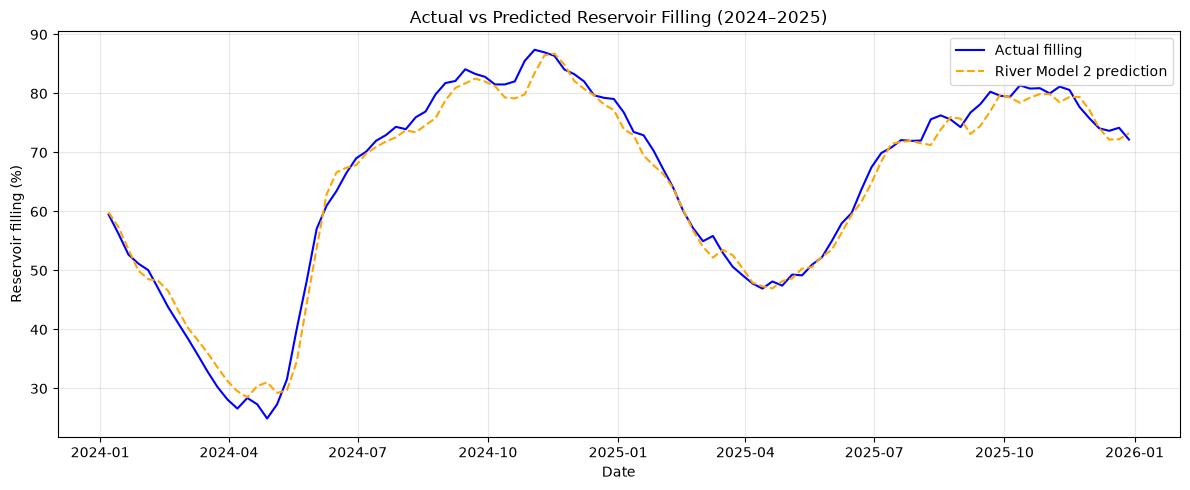

In [51]:
import matplotlib.pyplot as plt

# Plot actual and predicted reservoir filling
plt.figure(figsize=(12, 5))

plt.plot(
    river_lag4_results.index,
    river_lag4_results["Actual"] * 100,
    label="Actual filling",
    color="blue"
)

plt.plot(
    river_lag4_results.index,
    river_lag4_results["Predicted"] * 100,
    label="River Model 2 prediction",
    color="orange",
    linestyle="--"
)

plt.title("Actual vs Predicted Reservoir Filling (2024–2025)")
plt.xlabel("Date")
plt.ylabel("Reservoir filling (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 5.1 Final Function for Predicting Fill-Level

In [52]:
# Display available reservoir regions
available_regions = (
    nve_df[["omrType", "omrnr"]]
    .drop_duplicates()
    .sort_values(["omrType", "omrnr"])
    .reset_index(drop=True)
)

display(available_regions)

,omrType,omrnr
0,EL,1
1,EL,2
2,EL,3
3,EL,4
4,EL,5
5,NO,0
6,VASS,1
7,VASS,2
8,VASS,3


In [58]:

import pandas as pd
import numpy as np
from river import linear_model, preprocessing, optim


def forecast_reservoir_filling(
    nve_data,
    region_type="NO",
    region_number=0,
    history_years=10,
    horizon_weeks=12,
    n_lags=8,
    learning_rate=0.01,
    data_sources=("NVE",),
    forecast_start=None
):
    """
    Forecast weekly reservoir filling using River linear regression.

    The model uses historical reservoir filling, lag features,
    and week number to predict future filling levels recursively.
    """

    # Check that the requested data source is supported
    if set(data_sources) != {"NVE"}:
        raise ValueError("This version only supports NVE data.")

    # Validate model parameters
    if history_years <= 0 or horizon_weeks <= 0 or n_lags < 1:
        raise ValueError("History, horizon and lag parameters must be positive.")

    if learning_rate <= 0:
        raise ValueError("Learning rate must be positive.")

    # Select the requested reservoir region
    region_df = nve_data[
        (nve_data["omrType"] == region_type) &
        (nve_data["omrnr"] == region_number)
    ][["dato_Id", "fyllingsgrad"]].copy()

    if region_df.empty:
        raise ValueError("No data found for the selected region.")

    # Prepare weekly reservoir filling data
    region_df["dato_Id"] = pd.to_datetime(region_df["dato_Id"])
    region_df = region_df.sort_values("dato_Id")
    region_df = region_df.drop_duplicates(subset="dato_Id")
    region_df = region_df.set_index("dato_Id")
    region_df = region_df.rename(columns={"fyllingsgrad": "filling"})

    # Determine the forecast starting point
    if forecast_start is None:
        forecast_start = region_df.index.max() + pd.Timedelta(weeks=1)
    else:
        forecast_start = pd.Timestamp(forecast_start)

    # Select only observations available before the forecast
    historical_df = region_df[region_df.index < forecast_start].copy()

    # Select the requested number of historical years
    history_start = forecast_start - pd.DateOffset(years=history_years)
    historical_df = historical_df[historical_df.index >= history_start]

    if len(historical_df) <= n_lags:
        raise ValueError("Not enough historical data for the selected settings.")

    # Check that the most recent observation is one week before the forecast
    expected_last_date = forecast_start - pd.Timedelta(weeks=1)

    if historical_df.index.max() != expected_last_date:
        raise ValueError(
            "Forecast must start one week after the latest available observation."
        )

    # Check for missing weeks in the historical data
    expected_dates = pd.date_range(
        start=historical_df.index.min(),
        end=historical_df.index.max(),
        freq="W-SUN"
    )

    if not historical_df.index.equals(expected_dates):
        raise ValueError("Historical data contains missing or irregular weeks.")

    # Create lag features
    model_df = historical_df.copy()

    for lag in range(1, n_lags + 1):
        model_df[f"lag_{lag}"] = model_df["filling"].shift(lag)

    # Add week number as a seasonal feature
    model_df["week"] = model_df.index.isocalendar().week.astype(int)

    # Remove observations without enough lag history
    model_df = model_df.dropna()

    # Define input features
    feature_columns = [
        f"lag_{lag}" for lag in range(1, n_lags + 1)
    ] + ["week"]

    # Create the River model
    river_model = (
        preprocessing.StandardScaler() |
        linear_model.LinearRegression(
            optimizer=optim.SGD(learning_rate)
        )
    )

    # Train the model on historical observations
    for _, row in model_df.iterrows():

        x = {
            feature: float(row[feature])
            for feature in feature_columns
        }

        y = float(row["filling"])

        river_model.learn_one(x, y)

    # Store the latest actual filling levels
    history = historical_df["filling"].tail(n_lags).tolist()

    # Create future weekly dates
    forecast_dates = pd.date_range(
        start=forecast_start,
        periods=horizon_weeks,
        freq="W-SUN"
    )

    predictions = []

    # Forecast future filling recursively
    for date in forecast_dates:

        x = {
            f"lag_{lag}": float(history[-lag])
            for lag in range(1, n_lags + 1)
        }

        x["week"] = float(date.isocalendar().week)

        # Predict the next week's filling
        prediction = river_model.predict_one(x)

        # Keep filling levels between 0 and 1
        prediction = float(np.clip(prediction, 0, 1))

        # Save prediction and use it for the next forecast
        predictions.append(prediction)
        history.append(prediction)

    # Create a DataFrame with forecast results
    forecast_df = pd.DataFrame({
        "Predicted": predictions
    }, index=forecast_dates)

    forecast_df.index.name = "date"

    return forecast_df


In [59]:
# Forecast 12 weeks using 10 years of historical NVE data
reservoir_forecast = forecast_reservoir_filling(
    nve_data=nve_df,
    region_type="NO",
    region_number=0,
    history_years=10,
    horizon_weeks=12,
    n_lags=4,
    learning_rate=0.01,
    data_sources=["NVE"],
    forecast_start="2024-01-07"
)

display(reservoir_forecast)

,Predicted
date,
2024-01-07,0.595430
2024-01-14,0.575763
2024-01-21,0.554103
2024-01-28,0.536912
2024-02-04,0.526228
2024-02-11,0.518139
2024-02-18,0.514655
2024-02-25,0.514199
2024-03-03,0.515795


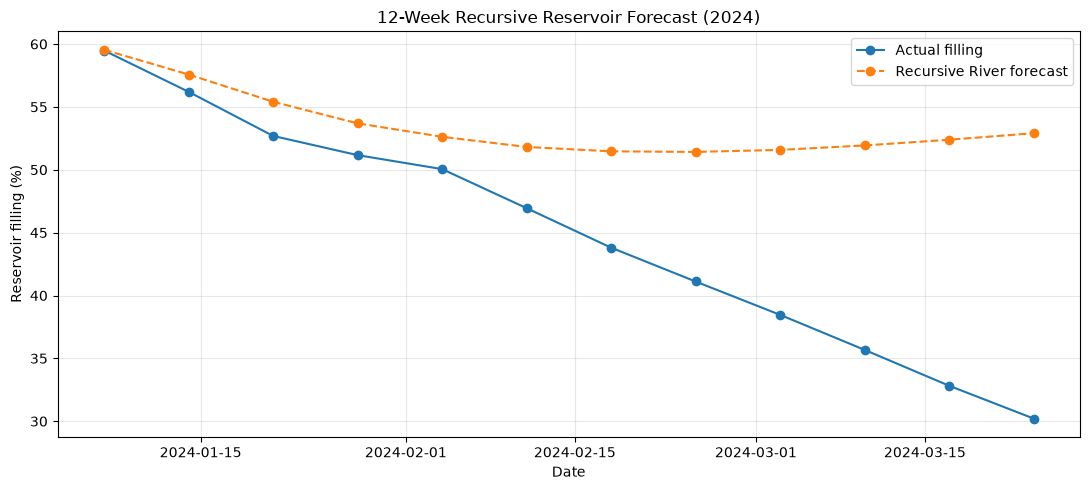

12-week forecast MAE: 8.64 percentage points


In [60]:
import matplotlib.pyplot as plt

# Select actual reservoir filling for the forecast period
actual_filling = forecast_df.loc[
    reservoir_forecast.index,
    "filling"
]

# Plot actual filling and recursive forecast
plt.figure(figsize=(11, 5))

plt.plot(
    actual_filling.index,
    actual_filling * 100,
    label="Actual filling",
    marker="o"
)

plt.plot(
    reservoir_forecast.index,
    reservoir_forecast["Predicted"] * 100,
    label="Recursive River forecast",
    marker="o",
    linestyle="--"
)

plt.title("12-Week Recursive Reservoir Forecast (2024)")
plt.xlabel("Date")
plt.ylabel("Reservoir filling (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate forecast error
forecast_mae = (
    actual_filling - reservoir_forecast["Predicted"]
).abs().mean() * 100

print(f"12-week forecast MAE: {forecast_mae:.2f} percentage points")

**Analysis:** The model is good at predicting short periods ahead, but when forecasting several weeks into the future, it has to use its own predictions as input instead of actual filling levels. This means that small errors can build up over time, causing the predictions to deviate more from the actual values. This is called **error accumulation** and is a common challenge in recursive forecasting.

In [61]:
import time

# Test different model configurations and forecast periods
test_results = []

for start_date in ["2023-01-08", "2024-01-07", "2025-01-05"]:
    for years, lags in [(5, 4), (10, 4), (10, 8), (20, 8)]:

        # Measure execution time
        start_time = time.perf_counter()

        # Generate a 12-week recursive forecast
        prediction = forecast_reservoir_filling(
            nve_data=nve_df,
            region_type="NO",
            region_number=0,
            history_years=years,
            horizon_weeks=12,
            n_lags=lags,
            learning_rate=0.01,
            data_sources=["NVE"],
            forecast_start=start_date
        )

        execution_time = time.perf_counter() - start_time

        # Compare predictions with actual observations
        actual = forecast_df.loc[prediction.index, "filling"]

        mae_value = (
            actual - prediction["Predicted"]
        ).abs().mean() * 100

        # Store evaluation results
        test_results.append({
            "Forecast start": start_date,
            "History (years)": years,
            "Lags": lags,
            "Horizon (weeks)": 12,
            "MAE (pp)": round(mae_value, 2),
            "Runtime (s)": round(execution_time, 3)
        })

# Display all results
test_results_df = pd.DataFrame(test_results)

display(test_results_df)

,Forecast start,History (years),Lags,Horizon (weeks),MAE (pp),Runtime (s)
0,2023-01-08,5,4,12,8.27,0.054
1,2023-01-08,10,4,12,6.12,0.151
2,2023-01-08,10,8,12,4.20,0.123
3,2023-01-08,20,8,12,4.74,0.104
4,2024-01-07,5,4,12,5.51,0.028
5,2024-01-07,10,4,12,8.64,0.045
6,2024-01-07,10,8,12,5.47,0.050
7,2024-01-07,20,8,12,4.21,0.081
8,2025-01-05,5,4,12,21.58,0.033
9,2025-01-05,10,4,12,8.69,0.055


I tested four different model configurations using 5, 10 and 20 years of historical data and 4 or 8 lag features. Each configuration was evaluated using a 12-week recursive forecast starting in January 2023, 2024 and 2025.

The best average result was achieved using 10 years of history and 8 lag features, with an average MAE of approximately 5.48 percentage points. The results also showed that using more historical data does not necessarily improve the predictions. All configurations had short execution times (below 0.13 seconds), suggesting that weekly data is a reasonable choice for the Streamlit application.

Based on these tests, I selected 10 years of history and 8 lag features as the default settings. However, the results may differ for other seasons and forecast horizons.

In [77]:

import numpy as np
import pandas as pd
from river import linear_model, preprocessing, optim


def prepare_weekly_weather(weather_data):
    """Convert hourly weather observations to weekly values."""

    weather = weather_data[
        ["time", "temperature_2m", "precipitation"]
    ].copy()

    weather["time"] = (
        pd.to_datetime(weather["time"], utc=True)
        .dt.tz_convert("Europe/Oslo")
        .dt.tz_localize(None)
    )

    # Average across geographical locations for each hour
    hourly = weather.groupby("time").agg(
        temperature=("temperature_2m", "mean"),
        precipitation=("precipitation", "mean")
    )

    # Weekly mean temperature and total precipitation
    weekly = hourly.resample("W-SUN").agg(
        temperature=("temperature", "mean"),
        precipitation=("precipitation", "sum")
    )

    return weekly.dropna()


def prepare_weekly_exchange(exchange_data):
    """Convert daily exchange rates to weekly averages."""

    exchange = exchange_data.copy()
    exchange["Date"] = pd.to_datetime(exchange["Date"])

    exchange = exchange.set_index("Date").sort_index()

    return exchange[["USD_NOK", "EUR_NOK"]].resample(
        "W-SUN"
    ).mean()


def forecast_reservoir_filling(
    nve_data,
    region="EL3",
    history_years=10,
    horizon_weeks=8,
    n_lags=8,
    learning_rate=0.01,
    data_sources=("NVE",),
    weather_data=None,
    exchange_data=None,
    forecast_start=None
):
    """
    Forecast weekly reservoir filling using River.

    Available sources:
    NVE, Open-Meteo, Norges Bank.

    Weather and exchange rates are optional.
    """

    sources = set(data_sources)

    if "NVE" not in sources:
        raise ValueError("NVE must always be included.")

    if not sources <= {"NVE", "Open-Meteo", "Norges Bank"}:
        raise ValueError("Unsupported data source.")

    if not 1 <= horizon_weeks <= 8:
        raise ValueError("Forecast horizon must be 1-8 weeks.")

    if history_years <= 0 or n_lags < 1 or learning_rate <= 0:
        raise ValueError("Invalid model parameters.")

    # Select the requested NVE area
    nve = nve_data.copy()
    nve["area"] = nve["omrType"] + nve["omrnr"].astype(str)

    region_df = nve.loc[
        nve["area"] == region,
        ["dato_Id", "fyllingsgrad"]
    ].copy()

    if region_df.empty:
        raise ValueError(f"No NVE data found for {region}.")

    region_df["dato_Id"] = pd.to_datetime(region_df["dato_Id"])

    region_df = (
        region_df.sort_values("dato_Id")
        .drop_duplicates("dato_Id")
        .set_index("dato_Id")
        .rename(columns={"fyllingsgrad": "filling"})
    )

    # Determine the first forecast week
    if forecast_start is None:
        forecast_start = region_df.index.max() + pd.Timedelta(weeks=1)
    else:
        forecast_start = pd.Timestamp(forecast_start)

    if forecast_start.dayofweek != 6:
        raise ValueError("Forecast start must be a Sunday.")

    history_start = forecast_start - pd.DateOffset(
        years=history_years
    )

    # Use historical NVE observations only
    model_data = region_df.loc[
        (region_df.index >= history_start) &
        (region_df.index < forecast_start)
    ].copy()

    if model_data.empty:
        raise ValueError("No historical filling data.")

    if model_data.index.max() != forecast_start - pd.Timedelta(weeks=1):
        raise ValueError("Missing NVE data before forecast start.")

    expected_dates = pd.date_range(
        model_data.index.min(),
        model_data.index.max(),
        freq="W-SUN"
    )

    if not model_data.index.equals(expected_dates):
        raise ValueError("NVE history contains missing weeks.")

    # Add optional weekly weather data
    extra_columns = []

    if "Open-Meteo" in sources:
        if weather_data is None:
            raise ValueError("Open-Meteo data is missing.")

        weekly_weather = prepare_weekly_weather(weather_data)

        model_data = model_data.join(weekly_weather)

        extra_columns += ["temperature", "precipitation"]

    # Add optional weekly exchange rates
    if "Norges Bank" in sources:
        if exchange_data is None:
            raise ValueError("Exchange rate data is missing.")

        weekly_exchange = prepare_weekly_exchange(exchange_data)

        model_data = model_data.join(weekly_exchange)

        extra_columns += ["USD_NOK", "EUR_NOK"]

    # Keep only complete weeks in the selected data sources
    model_data = model_data.dropna(subset=extra_columns)

    if model_data.empty:
        raise ValueError("No overlapping data for selected sources.")

    # Require consecutive observations
    expected_dates = pd.date_range(
        model_data.index.min(),
        model_data.index.max(),
        freq="W-SUN"
    )

    if not model_data.index.equals(expected_dates):
        raise ValueError("Selected data sources contain missing weeks.")

    if len(model_data) <= n_lags + 8:
        raise ValueError("Not enough overlapping training data.")

    # Create filling lag features
    for lag in range(1, n_lags + 1):
        model_data[f"lag_{lag}"] = model_data["filling"].shift(lag)

    features = [f"lag_{lag}" for lag in range(1, n_lags + 1)]

    # Represent the annual seasonal cycle
    week_numbers = model_data.index.isocalendar().week.astype(int)

    model_data["season_sin"] = np.sin(
        2 * np.pi * week_numbers / 52.18
    )
    model_data["season_cos"] = np.cos(
        2 * np.pi * week_numbers / 52.18
    )

    features += ["season_sin", "season_cos"]

    # Use previous week's weather/exchange data
    # to avoid using future observations during training
    for column in extra_columns:
        lag_name = f"{column}_lag1"
        model_data[lag_name] = model_data[column].shift(1)
        features.append(lag_name)

    # Save historical external variables for future scenarios
    external_history = model_data[extra_columns].copy()

    training_data = model_data.dropna(
        subset=features + ["filling"]
    )

    if training_data.empty:
        raise ValueError("No complete training observations.")

    # Initialize the River regression model
    river_model = (
        preprocessing.StandardScaler() |
        linear_model.LinearRegression(
            optimizer=optim.SGD(learning_rate)
        )
    )

    # Train using chronological weekly observations
    for _, row in training_data.iterrows():
        x = {
            feature: float(row[feature])
            for feature in features
        }

        river_model.learn_one(x, float(row["filling"]))

    # Prepare recursive forecasts
    filling_history = model_data["filling"].tail(n_lags).tolist()

    forecast_dates = pd.date_range(
        start=forecast_start,
        periods=horizon_weeks,
        freq="W-SUN"
    )

    predictions = []

    for step, date in enumerate(forecast_dates):

        x = {
            f"lag_{lag}": float(filling_history[-lag])
            for lag in range(1, n_lags + 1)
        }

        week = int(date.isocalendar().week)

        x["season_sin"] = float(
            np.sin(2 * np.pi * week / 52.18)
        )
        x["season_cos"] = float(
            np.cos(2 * np.pi * week / 52.18)
        )

        # First forecast uses the latest observed external data.
        # Later forecasts use historical averages for the
        # corresponding calendar week, not future observations.
        for column in extra_columns:
            if step == 0:
                value = external_history[column].iloc[-1]
            else:
                previous_week = int(
                    (date - pd.Timedelta(weeks=1)).isocalendar().week
                )

                same_week = external_history.loc[
                    external_history.index.isocalendar().week
                    == previous_week,
                    column
                ]

                if same_week.empty:
                    value = external_history[column].mean()
                else:
                    value = same_week.mean()

            x[f"{column}_lag1"] = float(value)

        prediction = river_model.predict_one(x)

        prediction = float(np.clip(prediction, 0, 1))

        predictions.append(prediction)
        filling_history.append(prediction)

    forecast_df = pd.DataFrame(
        {"Predicted": predictions},
        index=forecast_dates
    )

    forecast_df.index.name = "date"

    return forecast_df


In [78]:
# Forecast reservoir filling for VASS1 using NVE
forecast = forecast_reservoir_filling(
    nve_data=nve_df,
    region="VASS1",
    history_years=10,
    horizon_weeks=8,
    n_lags=8,
    learning_rate=0.01,
    data_sources=["NVE"],
    forecast_start="2025-01-05"
)

display(forecast)

C:\Users\Simone\AppData\Local\Temp\ipykernel_10368\3485378151.py:109: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  if forecast_start.dayofweek != 6:


,Predicted
date,
2025-01-05,0.723018
2025-01-12,0.693046
2025-01-19,0.661394
2025-01-26,0.628028
2025-02-02,0.594212
2025-02-09,0.560606
2025-02-16,0.527105
2025-02-23,0.495245


In [80]:
# Compare predicted and actual reservoir filling
actual = nve_df[
    (nve_df["omrType"] == "VASS") &
    (nve_df["omrnr"] == 1)
][["dato_Id", "fyllingsgrad"]].copy()

actual["dato_Id"] = pd.to_datetime(actual["dato_Id"])

actual = actual.set_index("dato_Id").rename(
    columns={"fyllingsgrad": "Actual"}
)

comparison = forecast.join(actual, how="left")

comparison["Error"] = abs(
    comparison["Predicted"] - comparison["Actual"]
)

display(comparison)

# Calculate mean absolute error in percentage points
mae = comparison["Error"].mean() * 100

print(f"MAE: {mae:.2f} percentage points")

,Predicted,Actual,Error
date,,,
2025-01-05,0.723018,0.743467,0.020449
2025-01-12,0.693046,0.707985,0.014939
2025-01-19,0.661394,0.684428,0.023034
2025-01-26,0.628028,0.651392,0.023364
2025-02-02,0.594212,0.612661,0.018448
2025-02-09,0.560606,0.572599,0.011993
2025-02-16,0.527105,0.525042,0.002063
2025-02-23,0.495245,0.487545,0.007700


MAE: 1.52 percentage points


In [82]:

import re
import warnings
import numpy as np
import pandas as pd

from river import linear_model, optim, preprocessing


def prepare_weekly_weather(weather_df):
    """Convert hourly Open-Meteo data into weekly weather observations."""

    weather = weather_df[
        ["time", "temperature_2m", "precipitation"]
    ].copy()

    # Convert timestamps to Norwegian local time
    weather["time"] = (
        pd.to_datetime(weather["time"], utc=True)
        .dt.tz_convert("Europe/Oslo")
        .dt.tz_localize(None)
    )

    # Average measurements across locations for each hour
    hourly = weather.groupby("time").agg(
        temp=("temperature_2m", "mean"),
        precip=("precipitation", "mean")
    )

    # Calculate weekly average temperature and total precipitation
    weekly = hourly.resample("W-SUN").agg(
        temp=("temp", "mean"),
        precip=("precip", "sum")
    )

    # Remove incomplete weeks
    hours_per_week = hourly["temp"].resample("W-SUN").count()
    weekly = weekly.loc[hours_per_week == 168]

    return weekly.dropna()


def prepare_weekly_exchange(exchange_rates_df):
    """Convert daily exchange rates into weekly averages."""

    fx = exchange_rates_df[
        ["Date", "USD_NOK", "EUR_NOK"]
    ].copy()

    fx["Date"] = pd.to_datetime(fx["Date"])

    fx = (
        fx.set_index("Date")
        .sort_index()
        .resample("W-SUN")
        .mean()
    )

    return fx.dropna()


def forecast_reservoir_filling(
    nve_data,
    area="EL3",
    history_years=10,
    horizon_weeks=8,
    n_lags=4,
    learning_rate=0.01,
    n_epochs=3,
    data_sources=("NVE",),
    weather_data=None,
    exchange_data=None,
    origin=None
):
    """
    Direct multi-horizon reservoir forecast using River.

    Trains one model per forecast horizon.
    Predicts changes in filling percentage points.

    Returns:
        forecast: DataFrame with predicted filling fractions
        info: Dictionary with training information
    """

    # Validate parameters
    sources = set(data_sources)
    allowed = {"NVE", "Open-Meteo", "Norges Bank"}

    if "NVE" not in sources:
        raise ValueError("NVE must always be included.")

    if not sources.issubset(allowed):
        raise ValueError("Unknown data source selected.")

    if not 1 <= horizon_weeks <= 8:
        raise ValueError("horizon_weeks must be between 1 and 8.")

    if history_years <= 0 or n_lags < 1:
        raise ValueError("Invalid history or lag parameters.")

    if learning_rate <= 0 or n_epochs < 1:
        raise ValueError("Invalid learning parameters.")

    # Identify the selected NVE area
    match = re.fullmatch(r"(EL|VASS|NO)(\d+)", area)

    if match is None:
        raise ValueError(f"Invalid area: {area}")

    area_type = match.group(1)
    area_number = int(match.group(2))

    region = nve_data.loc[
        (nve_data["omrType"] == area_type) &
        (nve_data["omrnr"] == area_number),
        ["dato_Id", "fyllingsgrad"]
    ].copy()

    if region.empty:
        raise ValueError(f"No NVE data found for {area}.")

    region["dato_Id"] = pd.to_datetime(region["dato_Id"])

    region = (
        region.sort_values("dato_Id")
        .drop_duplicates("dato_Id")
        .set_index("dato_Id")
    )

    # Use percentage points internally: 0.70 becomes 70
    fill = region["fyllingsgrad"].astype(float) * 100
    fill = fill.rename("fill")

    # Determine the last known NVE observation
    if origin is None:
        origin = fill.index.max()
    else:
        origin = pd.Timestamp(origin)

    if origin.dayofweek != 6:
        raise ValueError("Origin must be a Sunday.")

    if origin not in fill.index:
        raise ValueError("No NVE observation at origin.")

    # Build the weekly training table
    table = fill.to_frame()

    table = table.reindex(
        pd.date_range(
            table.index.min(),
            origin,
            freq="W-SUN"
        )
    )

    # Add historical weather if selected
    if "Open-Meteo" in sources:

        if weather_data is None:
            raise ValueError("Open-Meteo data is missing.")

        if area != "EL3":
            raise ValueError(
                "The loaded NO3 weather data are only "
                "mapped to EL3 in this notebook."
            )

        weekly_weather = prepare_weekly_weather(weather_data)

        table = table.join(weekly_weather[["temp", "precip"]])

    # Add historical exchange rates if selected
    if "Norges Bank" in sources:

        if exchange_data is None:
            raise ValueError("Norges Bank data is missing.")

        weekly_fx = prepare_weekly_exchange(exchange_data)

        table = table.join(weekly_fx[["USD_NOK", "EUR_NOK"]])

    # Keep only observations available by forecast origin
    table = table.loc[:origin]

    # Create input features for each historical week
    X = pd.DataFrame(index=table.index)

    # Current filling level is known at each forecast origin
    X["level"] = table["fill"]

    # Recent weekly changes in reservoir filling
    weekly_change = table["fill"].diff()

    for lag in range(1, n_lags + 1):
        X[f"change_lag_{lag}"] = weekly_change.shift(lag - 1)

    # Seasonal features
    angle = (
        2 * np.pi *
        table.index.dayofyear.to_numpy() / 365.25
    )

    X["season_sin"] = np.sin(angle)
    X["season_cos"] = np.cos(angle)

    # Weather information available at each historical origin
    if "Open-Meteo" in sources:
        X["precip_4w"] = (
            table["precip"].rolling(4, min_periods=4).sum()
        )

        X["temp_4w"] = (
            table["temp"].rolling(4, min_periods=4).mean()
        )

    # Exchange rate changes over the previous four weeks
    if "Norges Bank" in sources:
        X["usd_change_4w"] = (
            np.log(table["USD_NOK"]).diff(4)
        )

        X["eur_change_4w"] = (
            np.log(table["EUR_NOK"]).diff(4)
        )

    # Check the features available at the forecast origin
    x_now = X.loc[origin]

    if x_now.isna().any():
        missing = x_now.index[x_now.isna()].tolist()
        raise ValueError(
            f"Missing features at forecast origin: {missing}"
        )

    # Start of requested training history
    history_start = origin - pd.DateOffset(
        years=history_years
    )

    predictions = []
    training_counts = []
    training_starts = []

    # Train one independent River model for each horizon
    for h in range(1, horizon_weeks + 1):

        # Target: change in filling after h weeks
        target = (
            table["fill"].shift(-h) - table["fill"]
        ).rename("target")

        # Use only historical feature rows and known targets
        training = (
            X.join(target)
            .loc[history_start:origin]
            .dropna()
        )

        if len(training) < 25:
            raise ValueError(
                f"Only {len(training)} training weeks for "
                f"horizon {h}. More historical data are needed."
            )

        if len(training) < 104:
            warnings.warn(
                f"Only {len(training)} training weeks for "
                f"horizon {h}. Forecast reliability may be low.",
                stacklevel=2
            )

        # Standardize features and fit regularized regression
        model = (
            preprocessing.StandardScaler() |
            linear_model.LinearRegression(
                optimizer=optim.SGD(learning_rate),
                l2=0.001
            )
        )

        feature_names = X.columns.tolist()

        # Train on chronological observations
        for epoch in range(n_epochs):
            for _, row in training.iterrows():

                features = {
                    name: float(row[name])
                    for name in feature_names
                }

                model.learn_one(
                    features,
                    float(row["target"])
                )

        # Predict the change directly from the origin
        current_features = {
            name: float(x_now[name])
            for name in feature_names
        }

        predicted_change = model.predict_one(current_features)

        predicted_level = (
            float(table.loc[origin, "fill"]) +
            float(predicted_change)
        )

        predictions.append(predicted_level / 100)

        training_counts.append(len(training))
        training_starts.append(training.index.min())

    # Create weekly forecast dates
    forecast_dates = pd.date_range(
        start=origin + pd.Timedelta(weeks=1),
        periods=horizon_weeks,
        freq="W-SUN"
    )

    forecast = pd.DataFrame(
        {"Predicted": predictions},
        index=forecast_dates
    )

    forecast.index.name = "date"

    info = {
        "area": area,
        "origin": origin,
        "data_sources": sorted(sources),
        "train_start": min(training_starts),
        "training_rows_by_horizon": training_counts,
        "history_years_requested": history_years,
        "horizon_weeks": horizon_weeks,
        "n_lags": n_lags
    }

    return forecast, info


In [83]:
# Test direct River forecasting using NVE data
forecast_nve, info_nve = forecast_reservoir_filling(
    nve_data=nve_df,
    area="VASS1",
    history_years=10,
    horizon_weeks=8,
    n_lags=4,
    learning_rate=0.01,
    n_epochs=3,
    data_sources=["NVE"],
    origin="2024-12-29"
)

display(forecast_nve)
print(info_nve)

C:\Users\Simone\AppData\Local\Temp\ipykernel_10368\1687896477.py:140: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  if origin.dayofweek != 6:
C:\Users\Simone\AppData\Local\Temp\ipykernel_10368\1687896477.py:201: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  table.index.dayofyear.to_numpy() / 365.25


,Predicted
date,
2025-01-05,0.745278
2025-01-12,0.715754
2025-01-19,0.676928
2025-01-26,0.632101
2025-02-02,0.586775
2025-02-09,0.539051
2025-02-16,0.496084
2025-02-23,0.460548


{'area': 'VASS1', 'origin': Timestamp('2024-12-29 00:00:00'), 'data_sources': ['NVE'], 'train_start': Timestamp('2015-01-04 00:00:00'), 'training_rows_by_horizon': [521, 520, 519, 518, 517, 516, 515, 514], 'history_years_requested': 10, 'horizon_weeks': 8, 'n_lags': 4}


In [84]:
# Test forecasting during spring snowmelt
forecast_spring, info_spring = forecast_reservoir_filling(
    nve_data=nve_df,
    area="VASS1",
    history_years=10,
    horizon_weeks=8,
    n_lags=4,
    learning_rate=0.01,
    n_epochs=3,
    data_sources=["NVE"],
    origin="2025-04-27"
)

display(forecast_spring)

C:\Users\Simone\AppData\Local\Temp\ipykernel_10368\1687896477.py:140: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  if origin.dayofweek != 6:
C:\Users\Simone\AppData\Local\Temp\ipykernel_10368\1687896477.py:201: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  table.index.dayofyear.to_numpy() / 365.25


,Predicted
date,
2025-05-04,0.403007
2025-05-11,0.421410
2025-05-18,0.440435
2025-05-25,0.464562
2025-06-01,0.496522
2025-06-08,0.531068
2025-06-15,0.569208
2025-06-22,0.613156


In [85]:

import re
import warnings
import numpy as np
import pandas as pd
from river import linear_model, optim, preprocessing


def forecast_reservoir_filling(
    nve_data,
    area="EL3",
    history_years=10,
    horizon_weeks=8,
    n_lags=4,
    learning_rate=0.01,
    n_epochs=3,
    data_sources=("NVE",),
    weather_weekly=None,
    flow_weekly=None,
    origin=None
):
    """
    Forecast weekly reservoir filling with River.

    NVE is mandatory.
    Optional sources:
        Open-Meteo: temp, precip
        ENTSO-E: import_mwh, export_mwh

    Optional DataFrames must use Sunday dates as their index.
    All features are historical and known at the forecast origin.
    """

    sources = set(data_sources)
    allowed = {"NVE", "Open-Meteo", "ENTSO-E"}

    if "NVE" not in sources:
        raise ValueError("NVE is mandatory.")

    if not sources.issubset(allowed):
        raise ValueError(f"Unknown sources: {sources - allowed}")

    if not 1 <= horizon_weeks <= 8:
        raise ValueError("horizon_weeks must be between 1 and 8.")

    if n_lags < 1 or history_years <= 0:
        raise ValueError("Invalid history or lag parameters.")

    if learning_rate <= 0 or n_epochs < 1:
        raise ValueError("Invalid learning parameters.")

    # Select NVE reservoir area
    match = re.fullmatch(r"(EL|VASS|NO)(\d+)", area)

    if match is None:
        raise ValueError(f"Invalid area: {area}")

    area_type, area_number = match.group(1), int(match.group(2))

    region = nve_data.loc[
        (nve_data["omrType"] == area_type) &
        (nve_data["omrnr"] == area_number),
        ["dato_Id", "fyllingsgrad"]
    ].copy()

    if region.empty:
        raise ValueError(f"No NVE data for {area}.")

    region["dato_Id"] = pd.to_datetime(region["dato_Id"])

    fill = (
        region.sort_values("dato_Id")
        .drop_duplicates("dato_Id")
        .set_index("dato_Id")["fyllingsgrad"]
        .astype(float) * 100
    ).rename("fill")

    # Choose forecast origin
    origin = (
        fill.index.max()
        if origin is None
        else pd.Timestamp(origin)
    )

    if origin not in fill.index:
        raise ValueError("Origin must be an observed NVE Sunday.")

    # Create weekly time series
    table = fill.reindex(
        pd.date_range(fill.index.min(), origin, freq="W-SUN")
    ).to_frame()

    # Join optional weather observations
    if "Open-Meteo" in sources:
        if weather_weekly is None:
            raise ValueError("weather_weekly is required.")

        required = {"temp", "precip"}
        if not required.issubset(weather_weekly.columns):
            raise ValueError("Weather needs temp and precip columns.")

        if area != "EL3":
            warnings.warn(
                "Verify that weather data match the selected NVE area."
            )

        table = table.join(weather_weekly[["temp", "precip"]])

    # Join optional electricity import/export
    if "ENTSO-E" in sources:
        if flow_weekly is None:
            raise ValueError("flow_weekly is required.")

        required = {"import_mwh", "export_mwh"}
        if not required.issubset(flow_weekly.columns):
            raise ValueError(
                "Flow data need import_mwh and export_mwh columns."
            )

        if not area.startswith("EL"):
            raise ValueError(
                "ENTSO-E area matching is currently supported "
                "for EL1–EL5 only."
            )

        table = table.join(
            flow_weekly[["import_mwh", "export_mwh"]]
        )

    # Build historical features
    X = pd.DataFrame(index=table.index)
    X["level"] = table["fill"]

    change = table["fill"].diff()

    for lag in range(1, n_lags + 1):
        X[f"change_lag_{lag}"] = change.shift(lag - 1)

    # Seasonal features
    angle = 2 * np.pi * table.index.dayofyear / 365.25
    X["season_sin"] = np.sin(angle)
    X["season_cos"] = np.cos(angle)

    # Weather over the last four weeks
    if "Open-Meteo" in sources:
        X["precip_4w"] = (
            table["precip"].rolling(4, min_periods=4).sum()
        )
        X["temp_4w"] = (
            table["temp"].rolling(4, min_periods=4).mean()
        )

    # Electricity flow over the last four weeks
    if "ENTSO-E" in sources:
        X["import_4w"] = (
            table["import_mwh"].rolling(4, min_periods=4).sum()
        )
        X["export_4w"] = (
            table["export_mwh"].rolling(4, min_periods=4).sum()
        )

    # Features at the forecast origin
    x_now = X.loc[origin]

    if x_now.isna().any():
        missing = x_now.index[x_now.isna()].tolist()
        raise ValueError(
            f"Missing features at forecast origin: {missing}"
        )

    history_start = origin - pd.DateOffset(years=history_years)

    predictions = []
    training_counts = []

    # Train an independent River model for each forecast horizon
    for h in range(1, horizon_weeks + 1):

        # Predict change in percentage points after h weeks
        target = (
            table["fill"].shift(-h) - table["fill"]
        ).rename("target")

        training = (
            X.join(target)
            .loc[history_start:origin]
            .dropna()
        )

        if len(training) < 25:
            raise ValueError(
                f"Only {len(training)} training weeks for "
                f"horizon {h}. More data are needed."
            )

        if len(training) < 104:
            warnings.warn(
                f"Only {len(training)} training weeks for "
                f"horizon {h}; predictions may be unreliable."
            )

        model = (
            preprocessing.StandardScaler() |
            linear_model.LinearRegression(
                optimizer=optim.SGD(learning_rate),
                l2=0.001
            )
        )

        feature_names = X.columns.tolist()

        # Train on observations in chronological order
        for epoch in range(n_epochs):
            for _, row in training.iterrows():
                features = {
                    name: float(row[name])
                    for name in feature_names
                }
                model.learn_one(features, float(row["target"]))

        current_features = {
            name: float(x_now[name])
            for name in feature_names
        }

        predicted_change = model.predict_one(current_features)

        predicted_level = (
            float(table.loc[origin, "fill"]) +
            float(predicted_change)
        )

        predictions.append(predicted_level / 100)
        training_counts.append(len(training))

    forecast_dates = pd.date_range(
        origin + pd.Timedelta(weeks=1),
        periods=horizon_weeks,
        freq="W-SUN"
    )

    forecast = pd.DataFrame(
        {"Predicted": predictions},
        index=forecast_dates
    )
    forecast.index.name = "date"

    info = {
        "area": area,
        "origin": origin,
        "data_sources": sorted(sources),
        "training_rows_by_horizon": training_counts,
        "history_years_requested": history_years
    }

    return forecast, info


In [86]:
forecast, info = forecast_reservoir_filling(
    nve_data=nve_df,
    area="VASS1",
    history_years=10,
    horizon_weeks=8,
    data_sources=["NVE"],
    origin="2025-04-27"
)

display(forecast)

C:\Users\Simone\AppData\Local\Temp\ipykernel_10368\340221419.py:139: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * table.index.dayofyear / 365.25


,Predicted
date,
2025-05-04,0.403007
2025-05-11,0.421410
2025-05-18,0.440435
2025-05-25,0.464562
2025-06-01,0.496522
2025-06-08,0.531068
2025-06-15,0.569208
2025-06-22,0.613156


<div style="background-color: #eaf3fa; padding: 22px; border-radius: 12px; border-left: 5px solid #4a90c3; color: #243746;">

<h3 style="margin-top: 0;">Choice of Forecasting Model</h3>

<p>
In the Jupyter Notebook, I experimented with River and tested different model settings. In the Streamlit application, I ended up using SARIMAX from Statsmodels instead.
</p>

<p>
I wanted to create an interactive forecasting tool where the user could change the model parameters, training period and forecast horizon. I also wanted to include prediction intervals to show the uncertainty of the forecast.
</p>

<p>
I experienced some challenges when including weather data in the forecasting model. Due to limited time, I decided to focus on getting the model to work using historical reservoir data. Including other data sources is something I would like to improve in the future.
</p>

</div>

## 6. Making a map of Norway for selection of areas

In [90]:
import geopandas as gpd
from pathlib import Path

# Shapefiles are located one folder above notebooks
shape_folder = Path("../data/Shapefile")

# Load existing shapefiles
price_areas = gpd.read_file(
    shape_folder / "Budområder" / "Budområder.shp"
)

nve_regions = gpd.read_file(
    shape_folder / "NVE_Region" / "NVE_Region.shp"
)

# Convert coordinates to WGS84 for GeoJSON
price_areas = price_areas.to_crs(epsg=4326)
nve_regions = nve_regions.to_crs(epsg=4326)

# Export GeoJSON files
price_areas.to_file(
    shape_folder / "price_areas.geojson",
    driver="GeoJSON"
)

nve_regions.to_file(
    shape_folder / "nve_regions.geojson",
    driver="GeoJSON"
)

print("GeoJSON files created successfully!")

# Inspect area identifiers
print("Price area columns:", price_areas.columns.tolist())
print("NVE region columns:", nve_regions.columns.tolist())

GeoJSON files created successfully!
Price area columns: ['objectid', 'budomr', 'globalid', 'st_area(sh', 'st_perimet', 'geometry']
NVE region columns: ['OBJECTID', 'REGION', 'REGIONNAVN', 'POSTNUMMER', 'POSTSTED', 'BESÃ\x98KSADR', 'ADRESSE', 'geometry']


In [91]:
print("Budområder:")
print(price_areas["budomr"].unique())

print("\nNVE-regioner:")
print(nve_regions[["REGION", "REGIONNAVN"]].drop_duplicates())

Budområder:
<ArrowStringArray>
['NO 1', 'NO 2', 'NO 3', 'NO 4', 'NO 5']
Length: 5, dtype: str

NVE-regioner:
  REGION         REGIONNAVN
0     RV        Region Vest
1     RM  Region Midt-Norge
2     RN        Region Nord
3    RÃ        Region Ãst
4     RS        Region SÃ¸r


## 7. Explanation of correlation in page 8

<div style="background-color: #eaf3fa; padding: 22px; border-radius: 12px; border-left: 5px solid #4a90c3; color: #243746;">

<h3 style="margin-top: 0;">Sliding Window Correlation – Findings and Reflection</h3>

<p>
I experimented with different settings in the sliding window correlation to see if I could find any interesting relationships between precipitation and reservoir fill levels. I chose to look at Norway as a whole (NO0).
</p>

<p>
When looking at precipitation and the weekly change in fill level, I noticed that the correlation changed quite a lot throughout 2024. During summer, the correlation reached approximately -0.55, while during autumn it reached approximately 0.9. I found the negative correlation a bit confusing at first, because I expected more precipitation to be associated with an increase in reservoir fill levels. However, other factors, such as snowmelt, temperature and electricity production, could also influence the results.
</p>

<p>
I then changed the reservoir variable to fill level and introduced a time lag of one week. The correlation was mostly positive, but there were still some variations throughout the year.
</p>

<p>
I also wanted to see what happened when I increased the window length from 12 to 30 weeks and changed the time lag to two weeks. The correlation became much smoother and remained positive throughout the displayed period, with values between approximately 0.1 and 0.62. A longer window includes more observations, which can make the correlation more stable, but it can also hide shorter seasonal changes. Since I changed both the window length and the time lag, I cannot say exactly how much each setting influenced the result.
</p>

<p>
Based on these observations, I think precipitation could be a useful variable for forecasting reservoir fill levels. However, the relationship seems to change throughout the year, and precipitation alone is probably not enough to make accurate predictions. It would therefore be interesting to include temperature and other relevant variables in further analysis.
</p>

</div>

## 8. Application Structure and Navigation

<img src="images/structure_of_app.png" width="700">